# EDA на полных данных

Проданные легковые лоты ЦДТ с одной машиной, опубликованные с 2024-01-01 (`data/processed/lots.parquet`). Цель - обосновать цифрами правила очистки в `src/dataset/build.py`. Тексты лотов не выводим.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import pandas as pd
from src.eda.load import load_lots
from src.eda import summary, text_patterns, plots

df = load_lots()
summary.period_summary(df)

лотов                        14909
первая публикация       2024-01-01
последняя публикация    2026-10-05
dtype: object

## 1. Таргет: цена продажи

In [2]:
summary.price_quantiles(df)

0.1%        4995.0
1.0%       15780.0
5.0%       41697.0
25.0%     150099.0
50.0%     333333.0
75.0%     650000.0
95.0%    1540000.0
99.0%    2803882.0
99.9%    6462082.0
Name: sale_price, dtype: float64

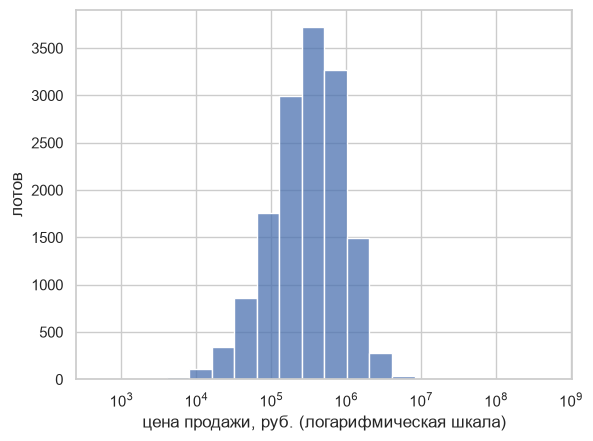

In [3]:
plots.plot_price_distribution(df);

Отношение цены продажи к начальной цене этапа. На аукционе цена не ниже стартовой, на публичном предложении не выше цены первого периода, поэтому отношение > 10 или < 0.05 подозрительно.

In [4]:
summary.ratio_thresholds(df)

,цена продажи / начальная цена этапа,лотов
0,> 1.5,540
1,> 2,228
2,> 3,90
3,> 5,38
4,> 10,13
5,< 0.3,517
6,< 0.2,164
7,< 0.1,19
8,< 0.05,4


In [5]:
summary.extreme_lots(df, "sale_price")

,tradeId,make,model,year,stage,lot_priceBegin,sale_price,price_ratio
12639,343814,Nissan,Teana,2011.0,публичное предложение,700000.0,521700000.0,745.29
14647,369773,Lada,4x4,2024.0,публичное предложение,675000.0,448838000.0,664.95
9927,314898,Chery,Tiggo 4 Pro,2023.0,публичное предложение,1278000.0,127999900.0,100.16
7123,283761,Mazda,3,2020.0,публичное предложение,1890000.0,14950000.0,7.91
13060,349174,Porsche,Panamera,2021.0,аукцион,11500000.0,11500000.0,1.00
4637,253567,Lexus,LX,NaN,аукцион,8521000.0,9373100.0,1.10
688,208631,BMW,X6,2020.0,аукцион,8546000.0,8546000.0,1.00
8044,294962,Porsche,Cayenne,2021.0,аукцион,7000000.0,8400000.0,1.20
9521,310041,BMW,X6,2020.0,аукцион,8000000.0,8000000.0,1.00
973,211673,Lexus,LX,2018.0,аукцион,7000000.0,7700000.0,1.10


In [6]:
summary.extreme_lots(df, "price_ratio")

,tradeId,make,model,year,stage,lot_priceBegin,sale_price,price_ratio
12639,343814,Nissan,Teana,2011.0,публичное предложение,700000.0,521700000.0,745.29
14647,369773,Lada,4x4,2024.0,публичное предложение,675000.0,448838000.0,664.95
9927,314898,Chery,Tiggo 4 Pro,2023.0,публичное предложение,1278000.0,127999900.0,100.16
4850,255756,Lexus,RX,2011.0,аукцион,50000.0,2332500.0,46.65
8091,295544,Chevrolet,Lanos,2009.0,аукцион,19000.0,733400.0,38.60
5389,262235,Nissan,March,2012.0,публичное предложение,7600.0,278901.0,36.70
3135,236888,Skoda,выпуска,2012.0,аукцион,7000.0,160650.0,22.95
13891,359665,Nissan,Vanette,1986.0,аукцион,5274.0,97041.6,18.40
14819,373942,Volkswagen,70,NaN,аукцион,7650.9,118958.4,15.55
4508,251809,Volkswagen,Multivan,1993.0,аукцион,12367.0,183031.6,14.80


In [7]:
summary.extreme_lots(df, "sale_price", largest=False)

,tradeId,make,model,year,stage,lot_priceBegin,sale_price,price_ratio
6001,269281,Lada,2107,2000.0,публичное предложение,45000.0,500.0,0.01
2166,225589,Lada,2114,NaN,публичное предложение,160000.0,1000.0,0.01
2169,225602,Lada,2104,1997.0,публичное предложение,9750.0,1950.0,0.20
2609,230680,Chrysler,PT,2003.0,публичное предложение,9000.0,2180.0,0.24
2477,229243,Citroen,выпуска,2011.0,публичное предложение,7407.0,2222.1,0.30
9900,314641,Lada,2107,2004.0,публичное предложение,99000.0,2800.0,0.03
7355,287092,Lada,2101,1979.0,аукцион,3000.0,3000.0,1.00
9643,311698,NaN,NaN,1990.0,публичное предложение,26000.0,3001.0,0.12
6840,280478,GAZ,31100,NaN,публичное предложение,33750.0,3375.0,0.10
6905,281222,Lada,2109,1990.0,публичное предложение,18000.0,3600.0,0.20


## 2. Этап продажи

In [8]:
summary.stage_summary(df)

,лотов,медиана_цены,медиана_отношения,один_участник
stage,,,,
аукцион,4748,478750.0,1.00,0.0
публичное предложение,10161,273000.0,0.72,0.5


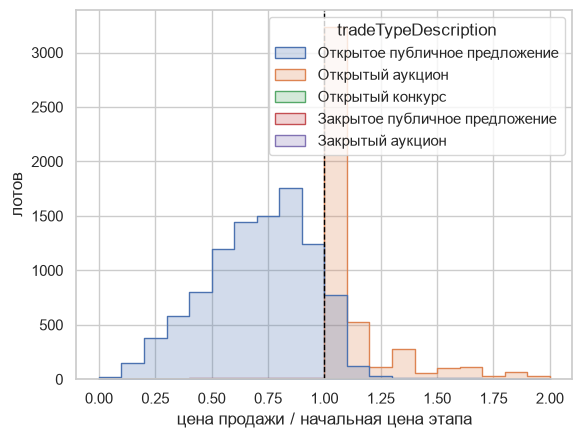

In [9]:
plots.plot_price_ratio(df);

## 3. Повторные продажи одной машины (VIN)

In [10]:
summary.vin_duplicates(df)

групп                                   453.00
лотов в группах                         934.00
медиана дней между продажами             97.00
один и тот же должник                     1.00
повтор после договора первой продажи      0.83
первая цена выше последней                0.87
dtype: float64

## 4. Покрытие признаков

In [11]:
summary.feature_coverage(df)

,доля лотов
make,0.965
model,0.959
year,0.983
vin_year_code,0.850
power_hp,0.173
engine_cc,0.122
lot_regionID,0.483
major_defect,0.053
damaged,0.058
no_keys_or_docs,0.007


In [12]:
summary.model_frequency(df)

,лотов на модель,моделей,доля лотов
0,1-1,572,0.04
1,2-4,290,0.05
2,5-19,208,0.14
3,20+,145,0.73


In [13]:
text_patterns.pattern_counts(df["lot_info"])

,лотов
доля в праве,19
слово местонахождение,227
местонахождение неизвестно (регулярка флага),0
не установлен(о),134
неизвестн,22
в розыске,0


## 5. От чего зависит цена

In [14]:
summary.age_slope(df)

лотов с возрастом                 14623
корреляция log цены и возраста    -0.62
наклон log цены за год           -0.098
изменение цены за год             -9.4%
dtype: object

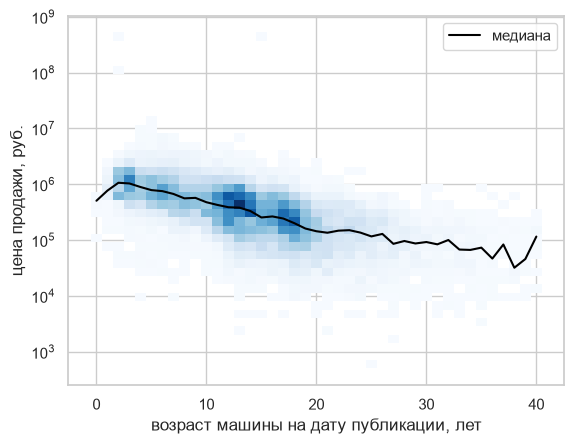

In [15]:
plots.plot_price_vs_age(df);

In [16]:
summary.flag_effect(df)

,лотов,цена с флагом / без,возраст с флагом,возраст без флага
флаг,,,,
major_defect,793,0.51,16.0,14.0
damaged,865,0.59,15.0,14.0
no_keys_or_docs,110,1.09,13.0,14.0
pledge,4024,1.73,12.0,15.0
arrest_or_ban,467,1.23,13.0,14.0
location_unknown,12,0.81,15.5,14.0


In [17]:
summary.quarter_summary(df)

,лотов,медиана_цены,медиана_возраста
quarter,,,
2024Q1,1150,353805.000,14.0
2024Q2,1042,326600.000,14.0
2024Q3,1240,354166.665,13.0
2024Q4,1212,339194.000,13.0
2025Q1,1278,318690.000,15.0
2025Q2,1157,300000.000,14.0
2025Q3,1647,311999.000,13.0
2025Q4,1582,350000.000,13.0
2026Q1,1641,322000.000,14.0


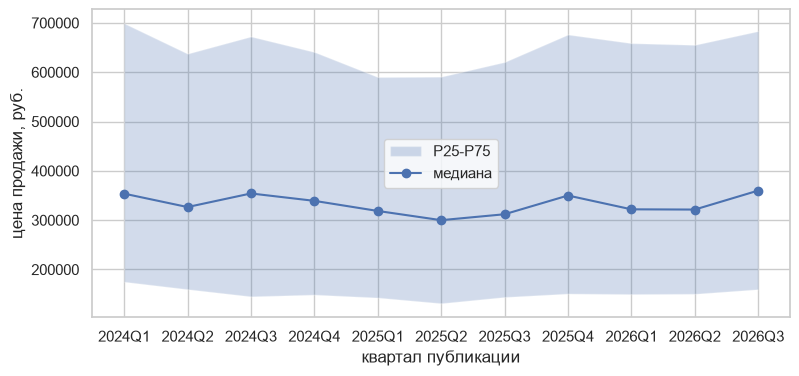

In [18]:
plots.plot_price_by_quarter(df);

## Выводы

1. Таргет сильно скошен (медиана 333 тыс., 99% - 2.8 млн), на логарифмической шкале распределение близко к симметричному: это подтверждает выбор log(цены).
2. Явные опечатки: три лота дороже 100 млн с отношением > 100 (лишние разряды или копейки). Высокое отношение само по себе не ошибка: дешёвый старт на аукционе с конкуренцией может дать рост в разы. Кандидат в правило: удалять отношение > 50 и цены, невозможные для марки и возраста.
3. Нижний хвост (цены 500-3000 руб., отношение до 0.01) похож на публичное предложение, дошедшее до цены отсечения. Это реальные продажи, но не рыночная цена машины.
4. Повторы по VIN: 453 группы, всегда один должник, в 83% повтор после договора первой продажи, в 87% первая цена выше. Это несостоявшийся договор и перевыставление: оставляем последнюю продажу.
5. Доля в праве (19 лотов по тексту) - продаётся не машина целиком, удаляем.
6. Флаг `location_unknown` не находит ни одного лота: регулярку надо проверить на dev.
7. Год есть в 95.5% лотов, мощность и объём только в 12%, регион в 48%. 858 моделей встречаются один раз: нужна нормализация моделей (например, модель «выпуска» у Skoda и Citroen - ошибка регулярки).
8. Возраст - главный фактор: около -9% цены за год. Залог и арест связаны с более высокой ценой из-за конфаундинга (это более новые кредитные машины), а не потому что залог повышает цену.
9. Медиана цены по кварталам стабильна (300-360 тыс.), сильного дрейфа нет. 2026Q3 неполный, 2026Q4 - 3 лота: отбрасываем последние 3 месяца по правилу валидации.